In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
print(os.cpu_count())

144


In [2]:
import numpy as np
import math
import random as rand
import statistics
import matplotlib.pyplot as plt
from tqdm import tqdm

# Summarize the results

In [3]:
nq_list = [10, 20, 30, 40, 50, 60, 70, 80]
num_train_list = [50, 100, 250, 500]
target_list = ["xy_corr_center", "xy_corr", "xxyy_nonlinear", "EE", "expXY"]

for num_train in num_train_list:
    for target in target_list:
        #SK
        mean_list = []
        stdv_list = []
        for nq in nq_list:
            x = np.load(f"results_temp/sk_{target}_N={nq}_nt={num_train}_normalize.npy")
            mean_list.append(x[1])
            stdv_list.append(x[2])
        np.save(f"results/SK_ndep_{target}_nt={num_train}_normalize.npy", np.array([nq_list, mean_list, stdv_list]))

        #TESK
        mean_list = []
        stdv_list = []
        for nq in nq_list:
            x = np.load(f"results_temp/tesk_{target}_N={nq}_nt={num_train}_normalize.npy")
            mean_list.append(x[1])
            stdv_list.append(x[2])
        np.save(f"results/TESK_ndep_{target}_nt={num_train}_normalize.npy", np.array([nq_list, mean_list, stdv_list]))

# Results

## n-dependence (xy_corr_center)

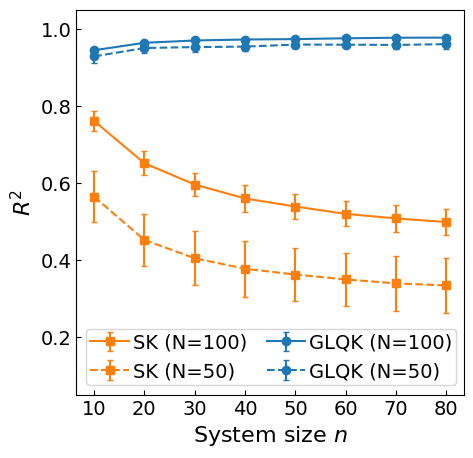

In [5]:
target = "xy_corr_center"
sk1 = np.load(f"results/SK_ndep_{target}_nt=100_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=50_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=100_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=50_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,1.05)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel(r"System size $n$", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=100)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=50)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=100)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=50)")

plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(ncol=2, fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## n-dependence (xxyy_nonlinear)

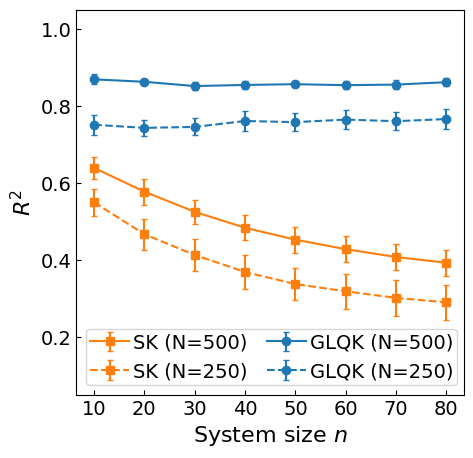

In [7]:
target = "xxyy_nonlinear"
sk1 = np.load(f"results/SK_ndep_{target}_nt=500_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=250_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=500_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=250_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,1.05)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel(r"System size $n$", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=500)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=250)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=500)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=250)")

plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(ncol=2, fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## n-dependence (xy_corr)

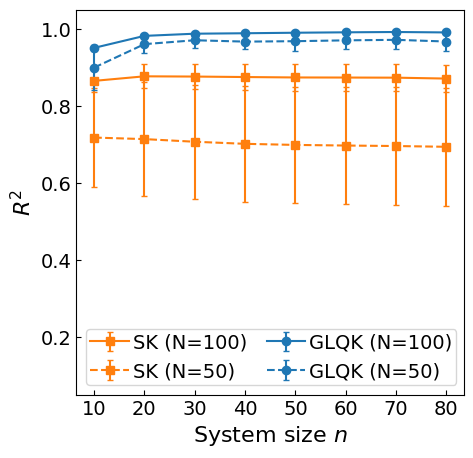

In [8]:
target = "xy_corr"
sk1 = np.load(f"results/SK_ndep_{target}_nt=100_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=50_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=100_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=50_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,1.05)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel(r"System size $n$", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=100)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=50)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=100)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=50)")

plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(ncol=2, fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## n-dependence (EE)

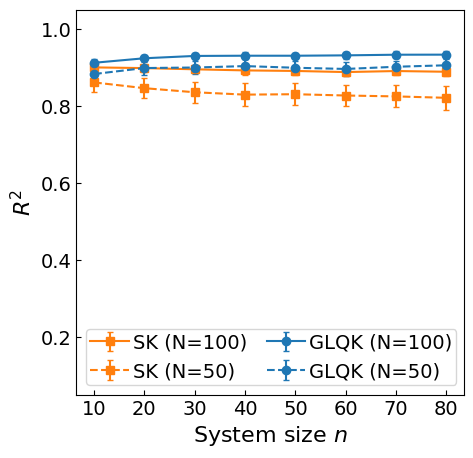

In [9]:
target = "EE"
sk1 = np.load(f"results/SK_ndep_{target}_nt=100_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=50_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=100_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=50_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,1.05)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel(r"System size $n$", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=100)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=50)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=100)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=50)")

plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(ncol=2, fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## n-dependence (expXY)

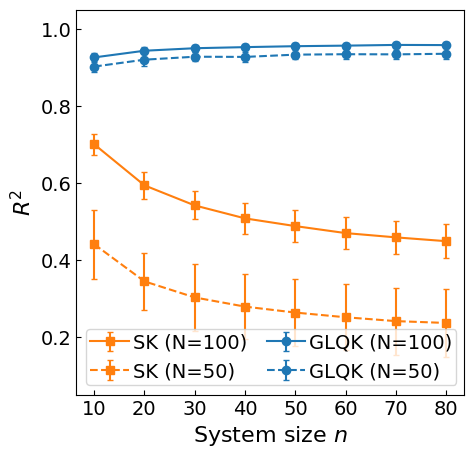

In [10]:
target = "expXY"
sk1 = np.load(f"results/SK_ndep_{target}_nt=100_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=50_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=100_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=50_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,1.05)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel(r"System size $n$", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=100)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=50)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=100)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=50)")

plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(ncol=2, fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots (xy_corr_center)

In [36]:
N=80 
num_train = 100
num_test = 500

target = "xy_corr_center"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.13240718902998636


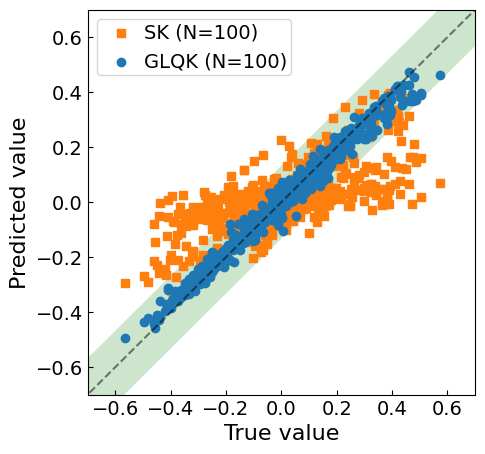

In [37]:
N=80 
num_train = 100
target = "xy_corr_center"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.7,0.7)
plt.ylim(-0.7,0.7)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=100)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=100)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots (xxyy_nonlinear)

In [44]:
N=80 
num_train = 500
num_test = 500

target = "xxyy_nonlinear"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.06262905765283505


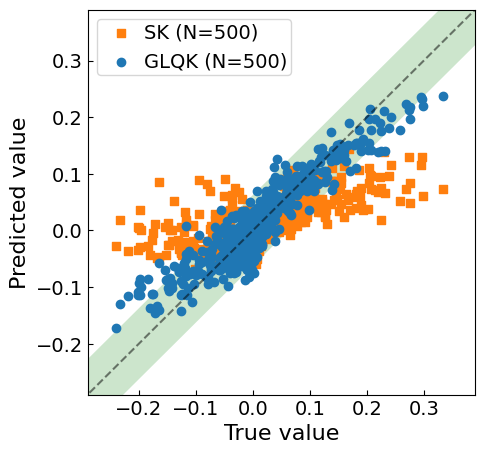

In [46]:
N=80 
num_train = 500
target = "xxyy_nonlinear"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.29,0.39)
plt.ylim(-0.29,0.39)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=500)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=500)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots (xy_corr)

In [47]:
N=80 
num_train = 100
num_test = 500

target = "xy_corr"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.13757816178991047


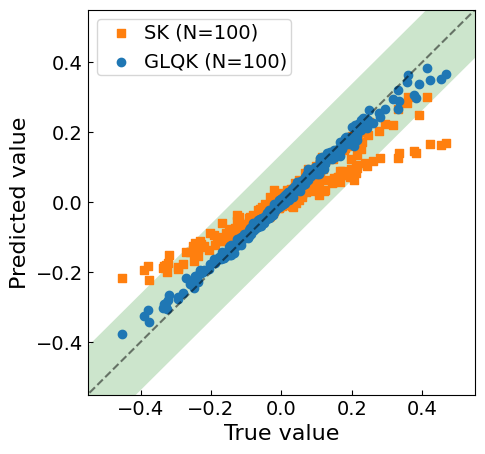

In [49]:
N=80 
num_train = 100
target = "xy_corr"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.55,0.55)
plt.ylim(-0.55,0.55)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=100)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=100)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots (EE)

In [50]:
N=80 
num_train = 100
num_test = 500

target = "EE"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.14443622314162247


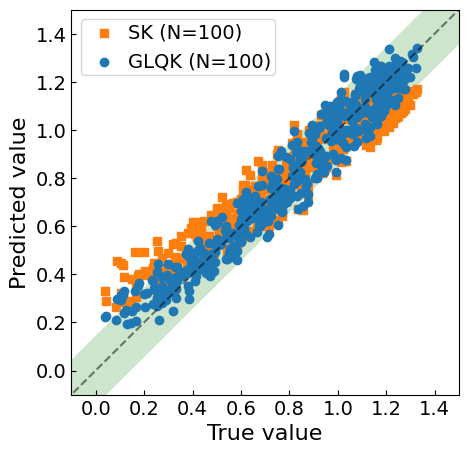

In [51]:
N=80 
num_train = 100
target = "EE"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.1,1.5)
plt.ylim(-0.1,1.5)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=100)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=100)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots (expXY)

In [52]:
N=80 
num_train = 100
num_test = 500

target = "expXY"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.14262722181369267


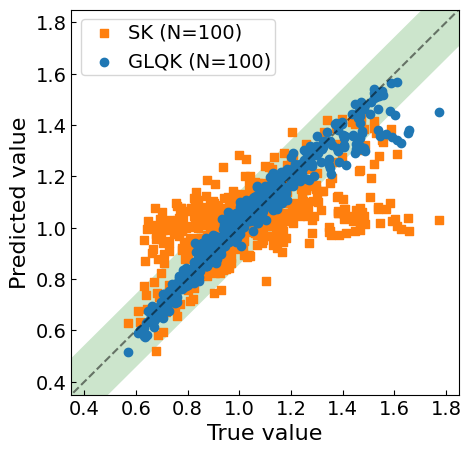

In [53]:
N=80 
num_train = 100
target = "expXY"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}_normalize.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(0.35,1.85)
plt.ylim(0.35,1.85)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=100)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=100)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)